## Import

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from kagglehub import KaggleDatasetAdapter

## Load Dataset

In [81]:
file_path = "ai_student_impact_dataset (1).csv"

df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "laveshjadon/ai-impact-on-students",
  file_path,
)

## Analisi descrittiva

In [82]:
df.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


In [83]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  50000 non-null  int64  
 1   Major_Category              50000 non-null  str    
 2   Year_of_Study               50000 non-null  str    
 3   Pre_Semester_GPA            50000 non-null  float64
 4   Weekly_GenAI_Hours          50000 non-null  float64
 5   Primary_Use_Case            50000 non-null  str    
 6   Prompt_Engineering_Skill    50000 non-null  str    
 7   Tool_Diversity              50000 non-null  int64  
 8   Paid_Subscription           50000 non-null  bool   
 9   Traditional_Study_Hours     50000 non-null  float64
 10  Perceived_AI_Dependency     50000 non-null  int64  
 11  Institutional_Policy        50000 non-null  str    
 12  Anxiety_Level_During_Exams  50000 non-null  int64  
 13  Post_Semester_GPA           50000 non-null

In [84]:
df.describe()

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,125000.500000,3.146102,8.427752,2.80026,11.209271,3.505360,4.270760,3.349299,75.798125
std,14433.901067,0.478854,8.269490,1.18802,5.156426,1.820812,2.144066,0.495673,13.281626
min,100001.000000,1.183000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000,10.780000
25%,112500.750000,2.834000,2.390000,2.00000,7.560000,2.000000,3.000000,3.023750,66.820000
50%,125000.500000,3.210000,5.800000,3.00000,11.180000,3.000000,4.000000,3.421000,76.000000
75%,137500.250000,3.521000,11.720000,4.00000,14.710000,5.000000,6.000000,3.749000,85.190000
max,150000.000000,3.998000,40.000000,5.00000,35.860000,10.000000,10.000000,4.000000,100.000000


descrizione documentazione feature del dataset

-student_ID: Unique numeric identifier assigned to each student (range: 100001–150000)

-Major Category: tudent's academic field — STEM, Business, Humanities, Medical, or Arts

-Year_of_Study: Current academic level — Freshman, Sophomore, Junior, Senior, or Graduate

-Pre_semester_GPA:Student's GPA at the start of the semester (Grade Point Average, scale: 1.0–4.0)

-Weekly_GENAI_Hours: Average hours per week the student spends using Generative AI tools (0–40 hrs)

-Primary_Use_Case: Main purpose for using AI — Copywriting, Summarizing, Debugging, Ideation, or Direct Answer

-Prompt_Engineering_Skill: Student's self-assessed AI prompting proficiency — Beginner, Intermediate, or Advanced

-Tool_Diversity: Number of distinct AI tools the student actively uses (scale: 1–5)

-Paid_Subscription:Whether the student holds a paid AI tool subscription (True or False)

-Traditional_Study_hours: Weekly hours spent studying without AI assistance (range: 1–36 hrs)

-Perceived_AI_Dependency: How much a students feel dependent on AI tools (range 1-10)

-Institutional_Policy : Institution's official AI usage policy — Allowed With Citation, Strict Ban, or Actively Encouraged

-Anxiety_Level_During_Exams : Self-reported exam anxiety score (scale: 1 = minimal to 10 = severe)

-Post_Semester_GPA : Student's GPA at the end of the semester (scale: 1.0–4.0)

-Skill_Retention_Score : Score measuring how well the student retained knowledge post-semester (0–100)

-Burnout_Risk_Level : Assessed risk of academic burnout — Low, Medium, or High

# EDA - Analisi demografica

In [85]:
df['Major_Category'].value_counts()

Major_Category
STEM          15059
Business      12538
Humanities     9994
Medical        6476
Arts           5933
Name: count, dtype: int64

In [86]:
totale_studenti = len(df)
media_gpa_globale = df['Pre_Semester_GPA'].mean()
media_ore_ai_globale = df['Weekly_GenAI_Hours'].mean()
media_ore_tradizionali = df['Traditional_Study_Hours'].mean()
percentuale_paid = (df['Paid_Subscription'].sum() / totale_studenti) * 100

print("--- INFRASTRUTTURA E METRICHE GENERALI ---")
print(f"Numero totale di studenti nel dataset: {totale_studenti:,}")
print(f"Media del GPA di tutto il campus: {media_gpa_globale:.2f} / 4.0")
print(f"Media ore settimanali passate su GenAI: {media_ore_ai_globale:.2f} ore")
print(f"Media ore settimanali di studio tradizionale: {media_ore_tradizionali:.2f} ore")
print(f"Percentuale di studenti con abbonamento Premium (Paid): {percentuale_paid:.1f}%")
print("-" * 50)

--- INFRASTRUTTURA E METRICHE GENERALI ---
Numero totale di studenti nel dataset: 50,000
Media del GPA di tutto il campus: 3.15 / 4.0
Media ore settimanali passate su GenAI: 8.43 ore
Media ore settimanali di studio tradizionale: 11.21 ore
Percentuale di studenti con abbonamento Premium (Paid): 42.3%
--------------------------------------------------


##Distribuzione numero studenti per Major

In [87]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

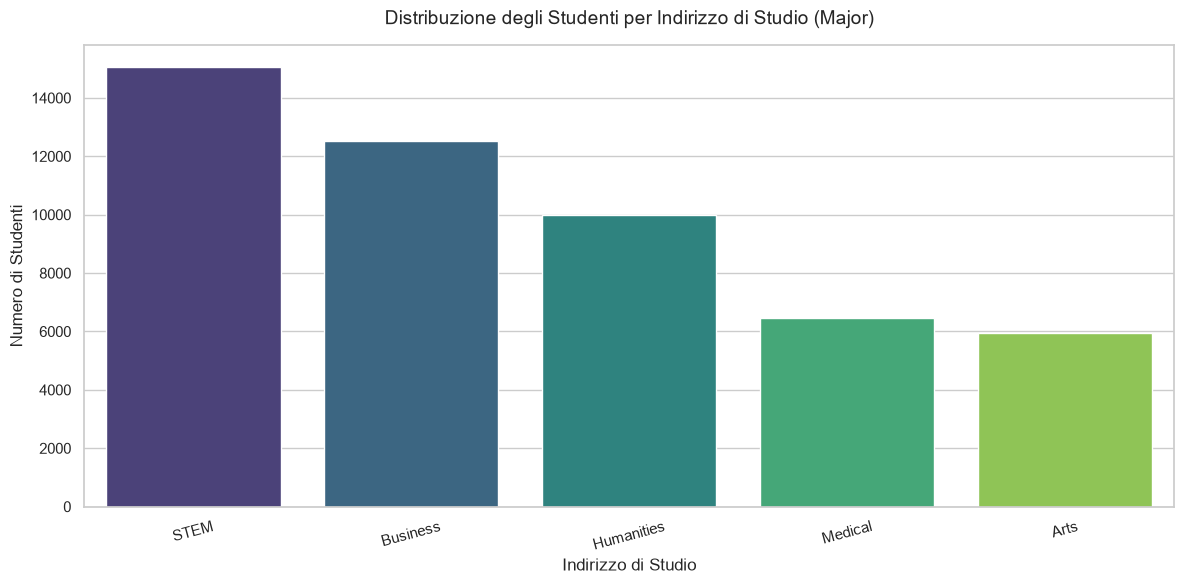

In [88]:
plt.figure()
# order definisce l'ordine decrescente in base al conteggio dei record
sns.countplot(
    data=df,
    x='Major_Category',
    order=df['Major_Category'].value_counts().index,
    palette='viridis'
)
plt.title('Distribuzione degli Studenti per Indirizzo di Studio (Major)', fontsize=14, pad=15)
plt.xlabel('Indirizzo di Studio', fontsize=12)
plt.ylabel('Numero di Studenti', fontsize=12)
plt.xticks(rotation=15) # Ruota leggermente i testi se si sovrappongono
plt.tight_layout()
plt.show()

La categoria Stem è decisamente quella più popolosa. Mentra la facolta Arts meno, con circa 6000 studenti su 50000

In [89]:
print("\n--- APPROFONDIMENTO: NUMERI PER OGNI FACOLTÀ ---")
# Calcoliamo quanti studenti ci sono per facoltà e la loro percentuale sul totale
conteggio_facolta = df['Major_Category'].value_counts()
percentuale_facolta = df['Major_Category'].value_counts(normalize=True) * 100

for facolta in conteggio_facolta.index:
    print(f"-> {facolta}: {conteggio_facolta[facolta]:,} studenti ({percentuale_facolta[facolta]:.1f}%)")
print("-" * 50)


--- APPROFONDIMENTO: NUMERI PER OGNI FACOLTÀ ---
-> STEM: 15,059 studenti (30.1%)
-> Business: 12,538 studenti (25.1%)
-> Humanities: 9,994 studenti (20.0%)
-> Medical: 6,476 studenti (13.0%)
-> Arts: 5,933 studenti (11.9%)
--------------------------------------------------


## Distribuzione GPA per Major Category

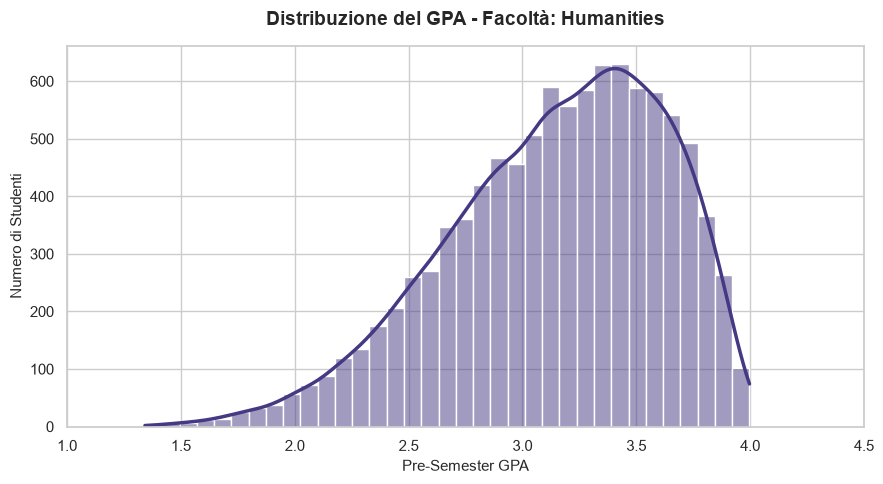

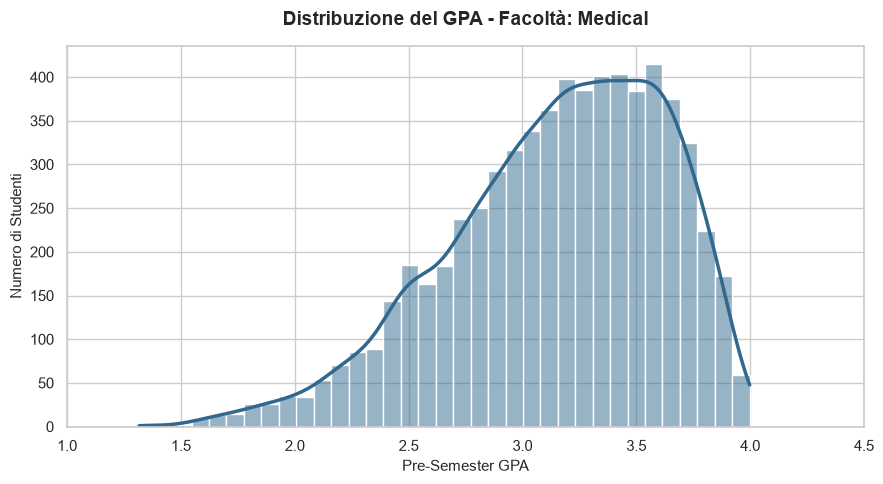

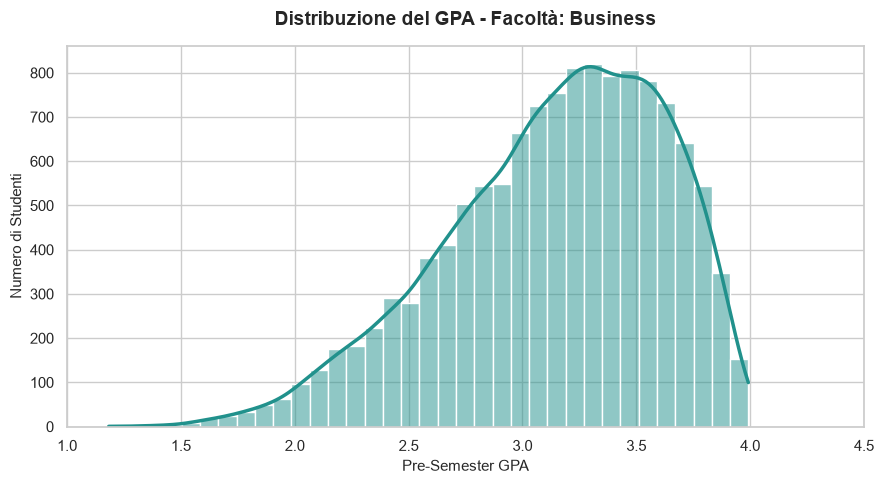

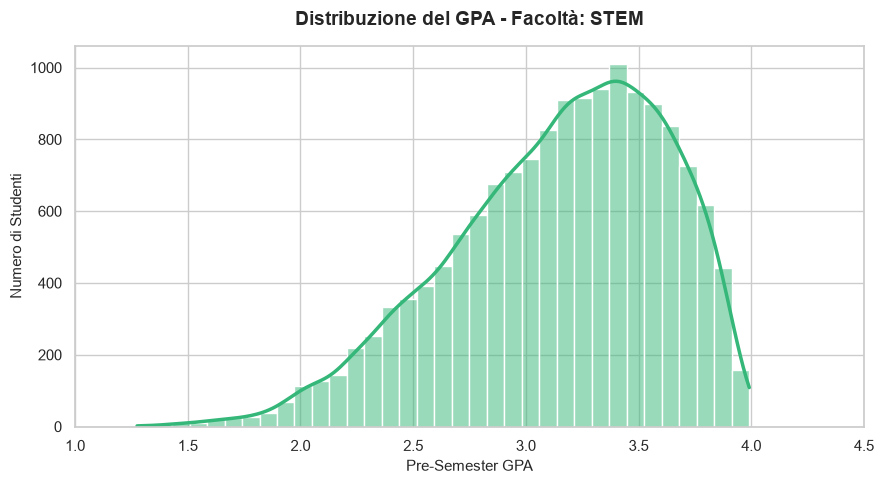

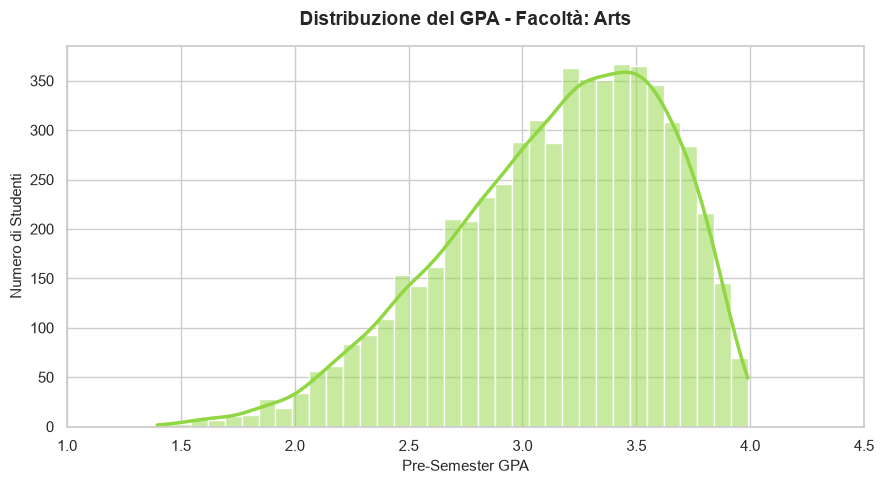

In [90]:
colori=sns.color_palette('viridis', len(df['Major_Category'].unique()))

#iterabile
categorie_facolta = df['Major_Category'].unique()
for i, facolta in enumerate(categorie_facolta):

    # print di controllo
    # print(f"--> elaborazione facoltà: {facolta} (Giro {i+1} di {len(categorie_facolta)})")

    # Crea una nuova figura pulita
    plt.figure(figsize=(9, 5))

    # Filtriamo il dataset
    dati_filtrati = df[df['Major_Category'] == facolta]

    # Disegniamo l'istogramma
    sns.histplot(
        data=dati_filtrati,
        x='Pre_Semester_GPA',
        kde=True,
        bins=35,
        color=colori[i],
        line_kws={'linewidth': 2.5}
    )

    # Titoli ed etichette
    plt.title(f'Distribuzione del GPA - Facoltà: {facolta}', fontsize=14, weight='bold', pad=15)
    plt.xlabel('Pre-Semester GPA', fontsize=11)
    plt.ylabel('Numero di Studenti', fontsize=11)

    # Fissiamo i limiti dell'asse X
    plt.xlim(1.0,4.5)

    plt.tight_layout()


    # Mostra il grafico corrente
    plt.show()

    # forzatura di chiusura per garantire integrità a tutti i grafici
    plt.close()

le curve sono pressoché sovrapponibili come forma della distribuizione, mostrandoci come in ogni facoltà in realtà ci sia una concentrazione di voti leggermente spostati da quello che è il valore medio del range di GPA, inoltre possiamo osservare come in quasi tutte le Major ci siano la stessa tipologia di studenti con il valore medio che si concentra verso il punto di 3.14

In [91]:
print("\n--- APPROFONDIMENTO: CHI HA IL GPA MEDIO PIÙ ALTO? ---")

# media GPA per ogni facoltà

gpa_per_facolta = df.groupby('Major_Category')['Pre_Semester_GPA'].mean().sort_values(ascending=False)
for facolta, gpa in gpa_per_facolta.items():
    print(f"-> Media GPA in {facolta}: {gpa:.3f}")
print("-" * 50)


--- APPROFONDIMENTO: CHI HA IL GPA MEDIO PIÙ ALTO? ---
-> Media GPA in Medical: 3.152
-> Media GPA in Humanities: 3.148
-> Media GPA in Arts: 3.147
-> Media GPA in STEM: 3.146
-> Media GPA in Business: 3.142
--------------------------------------------------


## Distribuzione Uso IA

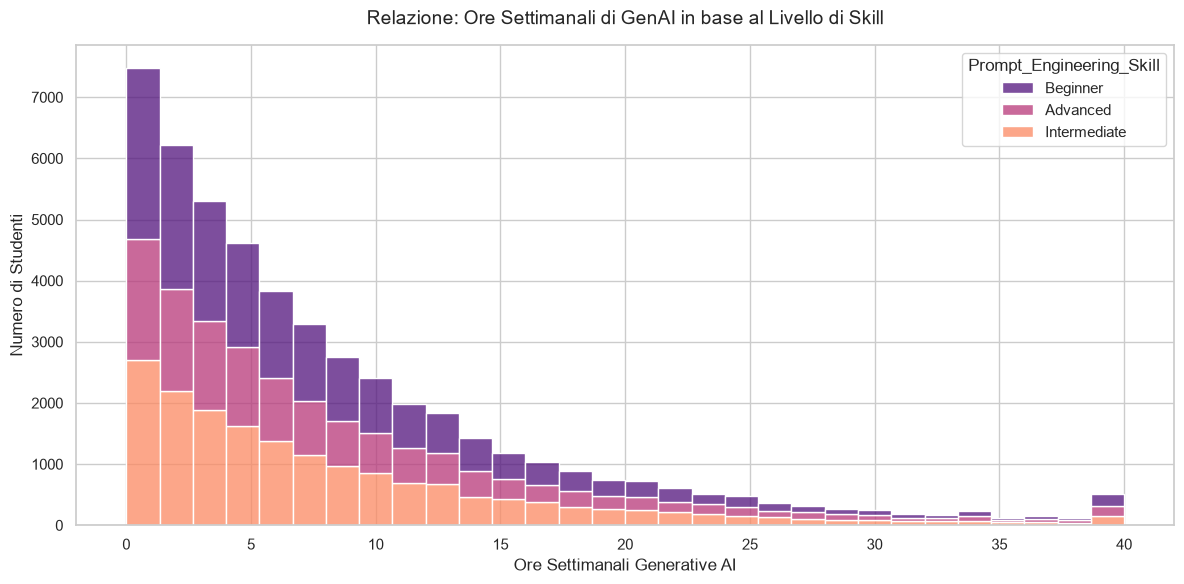

In [92]:
plt.figure()

sns.histplot(
    data=df,
    x='Weekly_GenAI_Hours',
    hue='Prompt_Engineering_Skill', #usa questa feature come hue di colore
    multiple='stack',               # multiple='stack' crea un istogramma a barre sovrapposte
    bins=30,
    palette='magma'
)
plt.title('Relazione: Ore Settimanali di GenAI in base al Livello di Skill', fontsize=14, pad=15)
plt.xlabel('Ore Settimanali Generative AI', fontsize=12)
plt.ylabel('Numero di Studenti', fontsize=12)
plt.tight_layout()
plt.show()


Dall'Istogramma Ore AI vs Skill: Chi ha skill "Advanced" (colore scuro/chiaro a seconda della palette) si concentra nella parte destra del grafico (tante ore)? Noterete visivamente se un alto numero di ore corrisponde effettivamente a un livello di competenza dichiarato più alto.

Dal grafico a barre possiamo dedurre come in realtà gli studenti che usano poco la generative AI sono molti, infatti la distribuzione concentra il numero maggiore degli studenti come sotto le 10 ore settimanali, quindi meno di due ore al giorno.

Tuttavia verso il fondo della distribuzioni c'è un leggero innalzamento della curva, mostrandoci come in realtà ci sia un cluster di studenti che usano molto l'AI(circa 40 ore alla settimana)

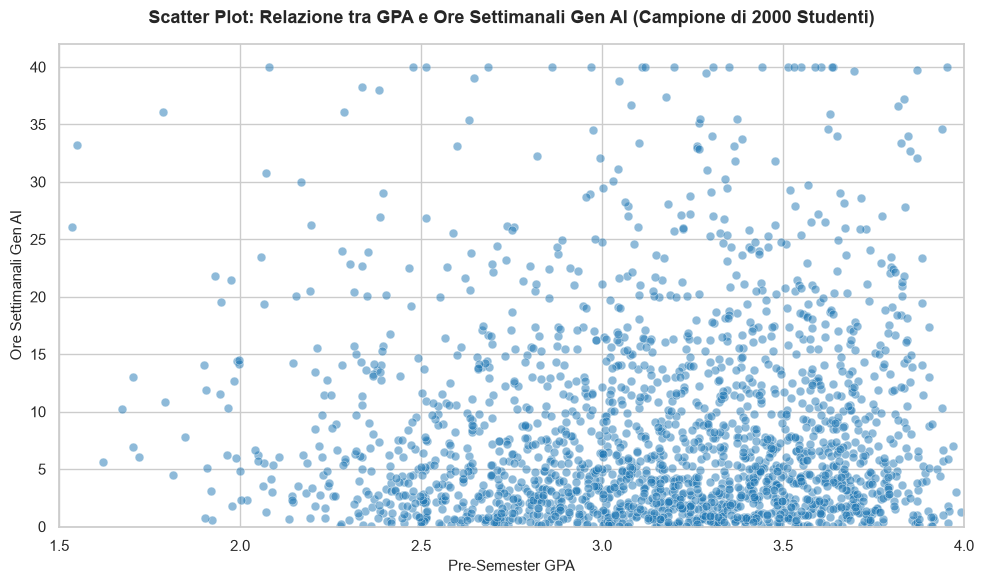

In [93]:
df_campione = df.sample(n=2000, random_state=42)

plt.figure(figsize=(10, 6))

# Creazione dello Scatter Plot
sns.scatterplot(
    data=df_campione,
    x='Pre_Semester_GPA',
    y='Weekly_GenAI_Hours',
    alpha=0.5,               # Trasparenza
    s=40,                    # Dimensione dei punti
    color='#1f77b4'          # scelta del colore
)

# Blocchiamo l'asse X fino a 4.0 esatto come per gli altri grafici
plt.xlim(1.5, 4.0)
plt.ylim(0, df['Weekly_GenAI_Hours'].max() + 2)

# Personalizzazione
plt.title('Scatter Plot: Relazione tra GPA e Ore Settimanali Gen AI (Campione di 2000 Studenti)', fontsize=13, weight='bold', pad=15)
plt.xlabel('Pre-Semester GPA', fontsize=11)
plt.ylabel('Ore Settimanali Gen AI', fontsize=11)

plt.tight_layout()
plt.show()
plt.close()

Dallo scatterplot possiamo vedere non solo una riconferma dell'analisi precedente ossia che pochi studenti in realtà usano l'AI dove la distribuzione di concentra praticamente tutta sotto le 20 ore settimanali. Non sembra che ci sia una qualche sorta di correlazione positiva ne negativa tra l'uso dell'AI e la GPA degli studenti.
La densità maggiore degli studenti si concentra sotto le 5 ore di utilizzo di Ai generativa e ha una media GPA compresa tra 2.5 e 3.5

In [94]:
#binnare per verificare i cluster studenteschi e capire dove ce ne sono di più con esatezza
df['Weekly_GenAI_Hours'].value_counts()

Weekly_GenAI_Hours
40.00    448
0.28      81
0.33      77
0.11      73
0.95      72
        ... 
38.30      1
36.69      1
32.09      1
35.33      1
29.82      1
Name: count, Length: 3566, dtype: int64

In [95]:
print("\n--- APPROFONDIMENTO: LE SKILL INFLUENZANO L'USO REALE? ---")
# Vediamo se chi si dichiara 'Advanced' passa davvero più ore rispetto ai 'Beginner'

ore_per_skill = df.groupby('Prompt_Engineering_Skill')['Weekly_GenAI_Hours'].mean().sort_values(ascending=False)
for skill, ore in ore_per_skill.items():
    print(f"-> Gli studenti con skill '{skill}' usano l'AI per una media di: {ore:.2f} ore/settimana")
print("="*100)


--- APPROFONDIMENTO: LE SKILL INFLUENZANO L'USO REALE? ---
-> Gli studenti con skill 'Advanced' usano l'AI per una media di: 8.69 ore/settimana
-> Gli studenti con skill 'Intermediate' usano l'AI per una media di: 8.37 ore/settimana
-> Gli studenti con skill 'Beginner' usano l'AI per una media di: 8.29 ore/settimana


l'utilizzo medio di ore a settimana è uniforme rispetto a chi si dichiara beginner o meno, leggermente superiore per gli advanced(fare il plot delle distribuzioni)

##Metriche Demografiche Avanzate

In [96]:
print("=" * 50)
print("   METRICHE DEMOGRAFICHE AVANZATE E PROFILAZIONE  ")
print("=" * 50)


# Analisi della distribuzione degli studenti per anno

print("\n--- 1) DISTRIBUZIONE PER ANNO DI CORSO (Year of Study) ---")
conteggio_anni = df['Year_of_Study'].value_counts()
percentuale_anni = df['Year_of_Study'].value_counts(normalize=True) * 100

for anno in conteggio_anni.index:
    print(f"-> {anno}: {conteggio_anni[anno]:,} studenti ({percentuale_anni[anno]:.1f}%)")
print("\n" + "-" * 50)


# Tabella di contingenza su: Facoltà / Anno di Studio
print("\n--- 2) INCROCIO: ANNO DI STUDIO PER OGNI FACOLTÀ (Percentuali) ---")
tabella_incrocio = pd.crosstab(df['Major_Category'], df['Year_of_Study'], normalize='index') * 100

print(tabella_incrocio.round(1).to_string())
print("\n" + "-" * 50)


# Analisi più accurata sulla variabilita del GPA per Facoltà

print("\n--- 3) DETTAGLIO STATISTICO DEL GPA PER FACOLTÀ ---")
# Aggreghiamo calcolando Media, Mediana e Deviazione Standard (std)
stats_gpa = df.groupby('Major_Category')['Pre_Semester_GPA'].agg(['mean', 'median', 'std'])

for facolta, row in stats_gpa.iterrows():
    print(f"-> Facoltà: {facolta}")
    print(f"   - Media GPA:    {row['mean']:.3f}")
    print(f"   - Mediana GPA:  {row['median']:.3f}")
    print(f"   - Dev. Standard: {row['std']:.3f} (Indica la dispersione dei voti)")
print("=" * 50)

   METRICHE DEMOGRAFICHE AVANZATE E PROFILAZIONE  

--- 1) DISTRIBUZIONE PER ANNO DI CORSO (Year of Study) ---
-> Junior: 11,045 studenti (22.1%)
-> Freshman: 11,031 studenti (22.1%)
-> Senior: 10,634 studenti (21.3%)
-> Sophomore: 9,860 studenti (19.7%)
-> Graduate: 7,430 studenti (14.9%)

--------------------------------------------------

--- 2) INCROCIO: ANNO DI STUDIO PER OGNI FACOLTÀ (Percentuali) ---
Year_of_Study   Freshman  Graduate  Junior  Senior  Sophomore
Major_Category                                               
Arts                21.6      14.2    22.3    21.9       19.9
Business            22.6      14.7    22.7    20.3       19.7
Humanities          21.8      15.2    22.0    21.6       19.5
Medical             22.6      14.7    21.6    20.9       20.2
STEM                21.8      15.1    21.8    21.7       19.6

--------------------------------------------------

--- 3) DETTAGLIO STATISTICO DEL GPA PER FACOLTÀ ---
-> Facoltà: Arts
   - Media GPA:    3.147
   - Med

La categoria più sottorappresentata è quella dei Graduate, tuttavia mantiene comunque dei valori comparabili

Dalla Tabella di Contingenza: Questa tabella mostra se la distribuzione degli anni di corso è omogenea in tutto il dataset o se ci sono anomalie.
Non percepisco anomalie

Dalla Deviazione Standard del GPA: Questo dato fa fare un salto di qualità all'analisi.

LE deviazioni standard sembrano in generale piuttosco contenute

Una Deviazione Standard bassa (es. 0.2) significa che quasi tutti gli studenti di quella facoltà hanno voti molto simili e vicini alla media.

Una Deviazione Standard alta (es. 0.6) significa che la facoltà è molto polarizzata: ci sono studenti con voti altissimi e studenti con voti bassissimi.

## Divisione in sotto DataFrame

In [97]:
dfTraditional = df[df['Weekly_GenAI_Hours'] < 2.0].copy()
dfSemiIA = df[(df['Weekly_GenAI_Hours'] >= 2.0) & (df['Weekly_GenAI_Hours'] < 15.0)].copy()
dfIA = df[df['Weekly_GenAI_Hours'] >= 15.0].copy()

dfTraditional.describe()

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,10683.000000,10683.000000,10683.000000,10683.000000,10683.000000,10683.000000,10683.000000,10683.000000,10683.000000
mean,125106.184124,3.145917,0.950901,2.785266,11.892422,2.450248,3.808949,3.333837,75.612773
std,14452.233656,0.479194,0.574386,1.192225,5.116638,1.244584,1.939380,0.493028,12.853050
min,100002.000000,1.342000,0.000000,1.000000,1.000000,1.000000,1.000000,1.316000,33.050000
25%,112690.500000,2.829000,0.450000,2.000000,8.230000,1.000000,2.000000,3.014500,66.725000
50%,125115.000000,3.209000,0.930000,3.000000,11.980000,2.000000,4.000000,3.402000,75.620000
75%,137711.500000,3.521000,1.440000,4.000000,15.380000,3.000000,5.000000,3.727000,84.675000
max,149988.000000,3.997000,1.990000,5.000000,35.860000,6.000000,10.000000,4.000000,100.000000


In [98]:
dfSemiIA.describe()

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,30775.000000,30775.000000,30775.000000,30775.000000,30775.000000,30775.000000,30775.000000,30775.000000,30775.000000
mean,124916.058457,3.146006,6.858193,2.798213,11.382603,3.255337,4.136734,3.362859,76.725605
std,14418.574355,0.478257,3.535554,1.189342,5.108083,1.465728,2.054172,0.490668,12.898829
min,100005.000000,1.183000,2.000000,1.000000,1.000000,1.000000,1.000000,1.190000,28.090000
25%,112416.500000,2.835000,3.830000,2.000000,7.820000,2.000000,3.000000,3.038000,67.900000
50%,124851.000000,3.210000,6.180000,3.000000,11.340000,3.000000,4.000000,3.435000,76.780000
75%,137335.000000,3.520000,9.470000,4.000000,14.830000,4.000000,6.000000,3.761000,85.910000
max,150000.000000,3.998000,14.990000,5.000000,31.130000,9.000000,10.000000,4.000000,100.000000


In [99]:
dfIA.describe()

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,8542.000000,8542.000000,8542.000000,8542.000000,8542.000000,8542.000000,8542.000000,8542.000000,8542.000000
mean,125172.551627,3.146682,23.433415,2.826387,9.730413,5.725708,5.331187,3.319784,72.688423
std,14465.408729,0.480635,7.132645,1.177668,5.100472,1.783779,2.355235,0.514754,14.620087
min,100001.000000,1.422000,15.000000,1.000000,1.000000,1.000000,1.000000,1.000000,10.780000
25%,112688.750000,2.837000,17.630000,2.000000,5.900000,4.000000,4.000000,2.983000,62.960000
50%,125399.000000,3.210000,21.360000,3.000000,9.650000,6.000000,5.000000,3.394000,73.235000
75%,137736.500000,3.522000,27.437500,4.000000,13.270000,7.000000,7.000000,3.731750,83.057500
max,149999.000000,3.994000,40.000000,5.000000,30.710000,10.000000,10.000000,4.000000,100.000000


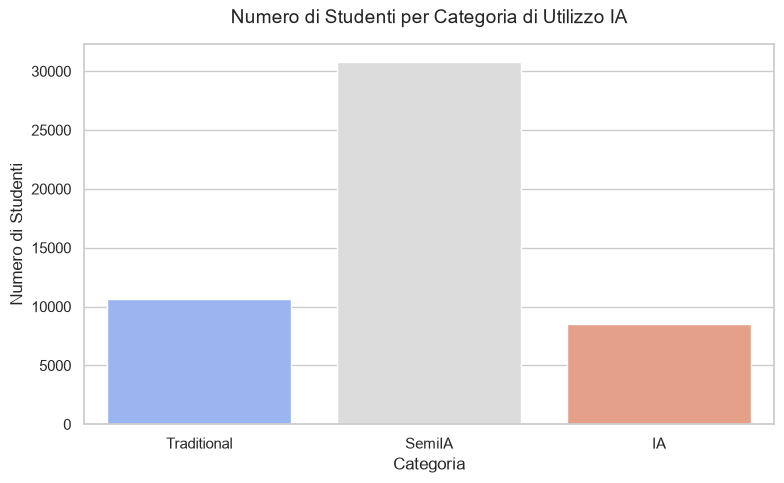

In [100]:
count_df = pd.DataFrame({
    'Category': ['Traditional', 'SemiIA', 'IA'],
    'Count': [len(dfTraditional), len(dfSemiIA), len(dfIA)]
})

plt.figure(figsize=(8, 5))
sns.barplot(data=count_df, x='Category', y='Count', palette='coolwarm')
plt.title('Numero di Studenti per Categoria di Utilizzo IA', fontsize=14, pad=15)
plt.xlabel('Categoria', fontsize=12)
plt.ylabel('Numero di Studenti', fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

Gia da questa prima divisione del dataset si evince come la maggior parte degli studenti di tutti gli anni sia ormai abbituata ad usare l'ia anche solo per fargli qualche domanda durante il suo periodo di studio

## Divisione tra le " Major_Category "

In [101]:
dfTraditional['Major_Category'].value_counts()

Major_Category
Business      2612
Humanities    2577
STEM          2542
Medical       1524
Arts          1428
Name: count, dtype: int64

In [102]:
dfSemiIA['Major_Category'].value_counts()

Major_Category
STEM          8788
Business      7889
Humanities    6304
Medical       4058
Arts          3736
Name: count, dtype: int64

In [103]:
dfIA['Major_Category'].value_counts()

Major_Category
STEM          3729
Business      2037
Humanities    1113
Medical        894
Arts           769
Name: count, dtype: int64

In [104]:
percentuale1 = (dfTraditional['Major_Category'].value_counts() / df['Major_Category'].value_counts()) * 100
percentuale2 = (dfSemiIA['Major_Category'].value_counts() / df['Major_Category'].value_counts()) * 100
percentuale3 = ((dfIA['Major_Category'].value_counts() / df['Major_Category'].value_counts()) * 100)

percentuale1.sort_values(ascending=False)

Major_Category
Humanities    25.785471
Arts          24.068768
Medical       23.533045
Business      20.832669
STEM          16.880271
Name: count, dtype: float64

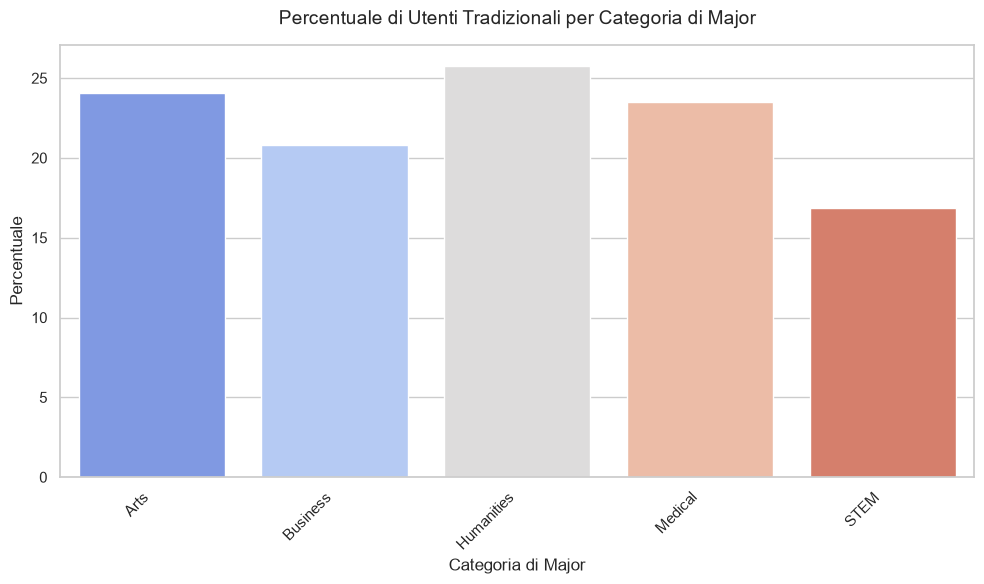

In [105]:
plt.figure(figsize=(10, 6))

custom_order = ['Arts', 'Business', 'Humanities', 'Medical', 'STEM']
percentuale1 = percentuale1.reindex(custom_order)

sns.barplot(x=percentuale1.index, y=percentuale1.values, palette='coolwarm', hue=percentuale1.index, legend=False)
plt.title('Percentuale di Utenti Tradizionali per Categoria di Major', fontsize=14, pad=15)
plt.xlabel('Categoria di Major', fontsize=12)
plt.ylabel('Percentuale', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [106]:
percentuale2.sort_values(ascending=False)

Major_Category
Humanities    63.077847
Arts          62.969830
Business      62.920721
Medical       62.662137
STEM          58.357129
Name: count, dtype: float64

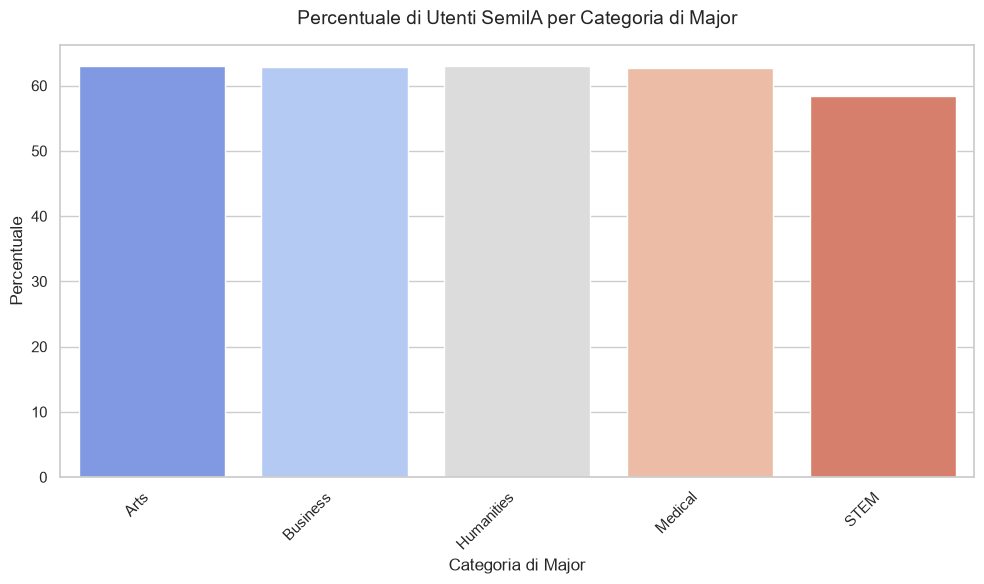

In [107]:
plt.figure(figsize=(10, 6))

custom_order = ['Arts', 'Business', 'Humanities', 'Medical', 'STEM']
percentuale2 = percentuale2.reindex(custom_order)

sns.barplot(x=percentuale2.index, y=percentuale2.values, palette='coolwarm', hue=percentuale2.index, legend=False)
plt.title('Percentuale di Utenti SemiIA per Categoria di Major', fontsize=14, pad=15)
plt.xlabel('Categoria di Major', fontsize=12)
plt.ylabel('Percentuale', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [108]:
percentuale3.sort_values(ascending=False)

Major_Category
STEM          24.762600
Business      16.246610
Medical       13.804818
Arts          12.961402
Humanities    11.136682
Name: count, dtype: float64

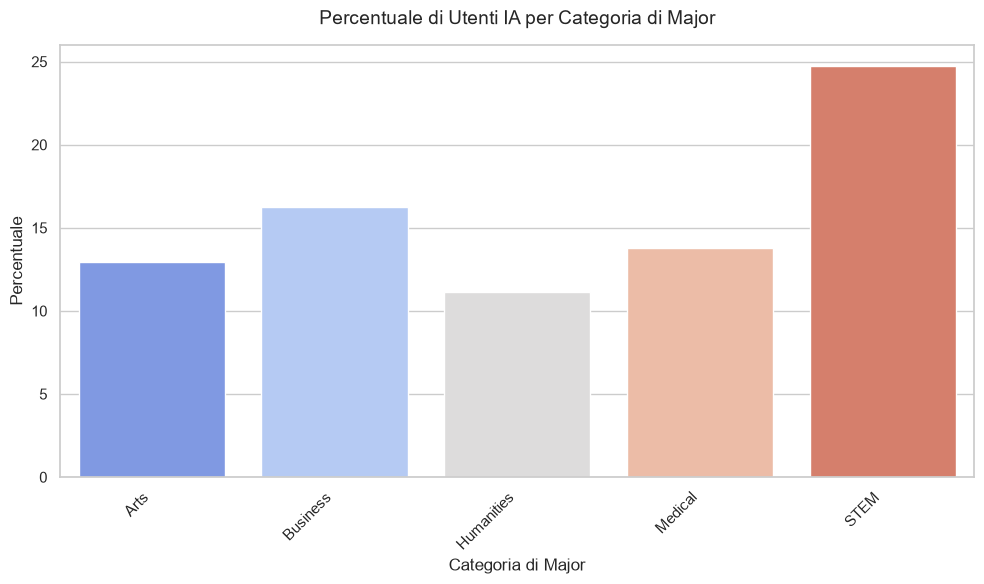

In [109]:
plt.figure(figsize=(10, 6))

custom_order = ['Arts', 'Business', 'Humanities', 'Medical', 'STEM']
percentuale3 = percentuale3.reindex(custom_order)

sns.barplot(x=percentuale3.index, y=percentuale3.values, palette='coolwarm', hue=percentuale3.index, legend=False)
plt.title('Percentuale di Utenti IA per Categoria di Major', fontsize=14, pad=15)
plt.xlabel('Categoria di Major', fontsize=12)
plt.ylabel('Percentuale', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Da quasta percentuale si capisce coma in modo molto lieve ma le materia piu tecniche e dove bisogna ripetere molte volte gli stessi compiti sono quelle piu soggette all'utilizzo dell'IA infatti senza molto stupore le facoltà dove viene usata meno l'IA sson quelle umanistica e artistica dove il pensiero umano e il vero fulcro delle ettivita

## Correlazione Voto / Utilizzo IA

In [110]:
voti_ia_cols = ["Weekly_GenAI_Hours", "Pre_Semester_GPA", "Traditional_Study_Hours"]
matrice_corr = df[voti_ia_cols].corr()
display(matrice_corr)

print("\nControllo delle corelazioni:")
valore = [matrice_corr.loc["Weekly_GenAI_Hours", "Pre_Semester_GPA"], matrice_corr.loc["Traditional_Study_Hours", "Pre_Semester_GPA"],matrice_corr.loc["Weekly_GenAI_Hours", "Traditional_Study_Hours"]]
for correlazione in valore:
  print(f"Il coefficiente è: {correlazione:.4f}")
  if correlazione > 0.3:
      print("\t-> Correlazione Positiva: All'aumentare dell'uso di IA, il GPA tende a salire.")
  elif correlazione < -0.3:
      print("\t-> Correlazione Negativa: All'aumentare dell'uso di IA, il GPA tende a scendere.")
  else:
      print("\t-> Correlazione Debole/Nulla: Non sembra esserci un legame lineare diretto tra le due variabili nel complesso.")

,Weekly_GenAI_Hours,Pre_Semester_GPA,Traditional_Study_Hours
Weekly_GenAI_Hours,1.000000,-0.001084,-0.157368
Pre_Semester_GPA,-0.001084,1.000000,-0.004620
Traditional_Study_Hours,-0.157368,-0.004620,1.000000



Controllo delle corelazioni:
Il coefficiente è: -0.0011
	-> Correlazione Debole/Nulla: Non sembra esserci un legame lineare diretto tra le due variabili nel complesso.
Il coefficiente è: -0.0046
	-> Correlazione Debole/Nulla: Non sembra esserci un legame lineare diretto tra le due variabili nel complesso.
Il coefficiente è: -0.1574
	-> Correlazione Debole/Nulla: Non sembra esserci un legame lineare diretto tra le due variabili nel complesso.


In [111]:
print("-" * 50 + "\n")
print("INDICE DI CORRELAZIONE DIVISO PER LIVELLO DI SKILL (dfTraditional)")
for skill in dfTraditional["Prompt_Engineering_Skill"].unique():
    sub_df = dfTraditional[dfTraditional["Prompt_Engineering_Skill"] == skill]
    corr_parziale = sub_df["Weekly_GenAI_Hours"].corr(sub_df["Pre_Semester_GPA"])
    print(f"Skill {skill:12}: Correlazione = {corr_parziale:.4f}")

print("\n" + "-" * 50 + "\n")
print("INDICE DI CORRELAZIONE DIVISO PER LIVELLO DI SKILL (dfSemiIA)")
for skill in dfSemiIA["Prompt_Engineering_Skill"].unique():
    sub_df = dfSemiIA[dfSemiIA["Prompt_Engineering_Skill"] == skill]
    corr_parziale = sub_df["Weekly_GenAI_Hours"].corr(sub_df["Pre_Semester_GPA"])
    print(f"Skill {skill:12}: Correlazione = {corr_parziale:.4f}")

print("\n" + "-" * 50 + "\n")
print("INDICE DI CORRELAZIONE DIVISO PER LIVELLO DI SKILL (dfIA)")
for skill in dfIA["Prompt_Engineering_Skill"].unique():
    sub_df = dfIA[dfIA["Prompt_Engineering_Skill"] == skill]
    corr_parziale = sub_df["Weekly_GenAI_Hours"].corr(sub_df["Pre_Semester_GPA"])
    print(f"Skill {skill:12}: Correlazione = {corr_parziale:.4f}")

print("\n" + "-" * 50)

--------------------------------------------------

INDICE DI CORRELAZIONE DIVISO PER LIVELLO DI SKILL (dfTraditional)
Skill Advanced    : Correlazione = -0.0017
Skill Intermediate: Correlazione = 0.0107
Skill Beginner    : Correlazione = -0.0040

--------------------------------------------------

INDICE DI CORRELAZIONE DIVISO PER LIVELLO DI SKILL (dfSemiIA)
Skill Advanced    : Correlazione = -0.0106
Skill Beginner    : Correlazione = 0.0147
Skill Intermediate: Correlazione = -0.0135

--------------------------------------------------

INDICE DI CORRELAZIONE DIVISO PER LIVELLO DI SKILL (dfIA)
Skill Beginner    : Correlazione = -0.0024
Skill Advanced    : Correlazione = 0.0000
Skill Intermediate: Correlazione = -0.0167

--------------------------------------------------


In [112]:
conditions = [
    df['Weekly_GenAI_Hours'] < 2,
    df['Weekly_GenAI_Hours'] >= 15
]
choices = ['Basso', 'Alto']
df['IAStudy'] = np.select(conditions, choices, default='Medio')

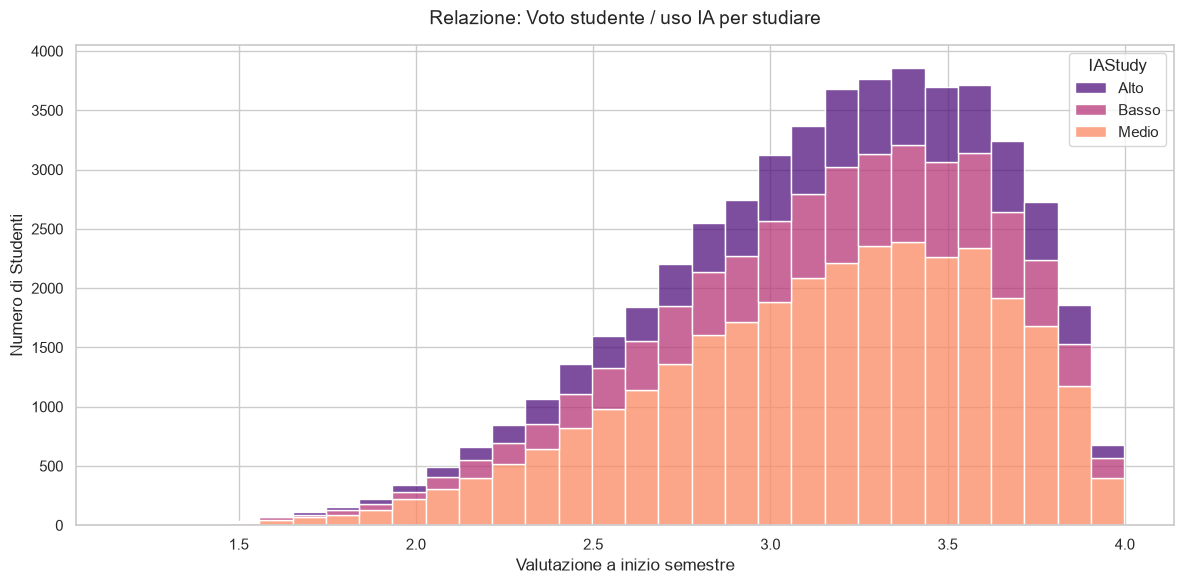

In [113]:
plt.figure()

sns.histplot(
    data=df,
    x='Pre_Semester_GPA',
    hue='IAStudy',
    multiple='stack',
    bins=30,
    palette='magma'
)
plt.title('Relazione: Voto studente / uso IA per studiare', fontsize=14, pad=15)
plt.xlabel('Valutazione a inizio semestre', fontsize=12)
plt.ylabel('Numero di Studenti', fontsize=12)
plt.tight_layout()
plt.show()

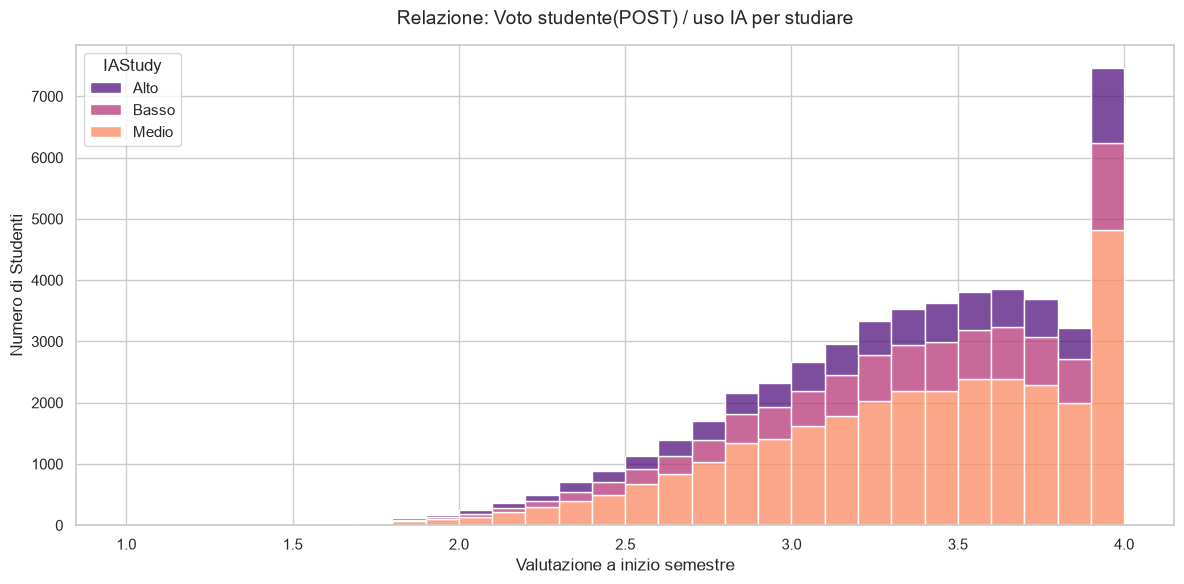

In [114]:
plt.figure()

sns.histplot(
    data=df,
    x='Post_Semester_GPA',
    hue='IAStudy',
    multiple='stack',
    bins=30,
    palette='magma'
)
plt.title('Relazione: Voto studente(POST) / uso IA per studiare', fontsize=14, pad=15)
plt.xlabel('Valutazione a inizio semestre', fontsize=12)
plt.ylabel('Numero di Studenti', fontsize=12)
plt.tight_layout()
plt.show()

## Voti Pre_Semester_GPA

In [115]:
print("-" * 50 + "\n")
print("Media Iniziale per studenti con basso utilizzo di IA \n")
gpa_facoltaTI = dfTraditional.groupby('Major_Category')['Pre_Semester_GPA'].mean()
for facolta, gpa in gpa_facoltaTI.items():
    print(f"-> Media GPA in {facolta}: {gpa:.3f}")

print("\n" + "-" * 50 + "\n")
print("Media Iniziale per studenti con medio utilizzo di IA \n")
gpa_facoltaSI = dfSemiIA.groupby('Major_Category')['Pre_Semester_GPA'].mean()
for facolta, gpa in gpa_facoltaSI.items():
    print(f"-> Media GPA Iniziale in {facolta}: {gpa:.3f}")

print("\n" + "-" * 50 + "\n")
print("Media Iniziale per studenti con alto utilizzo di IA \n")
gpa_facoltaII = dfIA.groupby('Major_Category')['Pre_Semester_GPA'].mean()
for facolta, gpa in gpa_facoltaII.items():
    print(f"-> Media GPA Iniziale in {facolta}: {gpa:.3f}")

print("\n" + "-" * 50)

--------------------------------------------------

Media Iniziale per studenti con basso utilizzo di IA 

-> Media GPA in Arts: 3.158
-> Media GPA in Business: 3.138
-> Media GPA in Humanities: 3.144
-> Media GPA in Medical: 3.146
-> Media GPA in STEM: 3.149

--------------------------------------------------

Media Iniziale per studenti con medio utilizzo di IA 

-> Media GPA Iniziale in Arts: 3.143
-> Media GPA Iniziale in Business: 3.142
-> Media GPA Iniziale in Humanities: 3.149
-> Media GPA Iniziale in Medical: 3.152
-> Media GPA Iniziale in STEM: 3.146

--------------------------------------------------

Media Iniziale per studenti con alto utilizzo di IA 

-> Media GPA Iniziale in Arts: 3.142
-> Media GPA Iniziale in Business: 3.145
-> Media GPA Iniziale in Humanities: 3.151
-> Media GPA Iniziale in Medical: 3.160
-> Media GPA Iniziale in STEM: 3.144

--------------------------------------------------


In [116]:
gpa_facoltaTot1 = (gpa_facoltaTI - gpa_facoltaII).sort_index(ascending=True)
for facolta, gpa in gpa_facoltaTot1.items():
    print(f"-> Differenza GPA in {facolta}: {gpa:.3f}")

-> Differenza GPA in Arts: 0.016
-> Differenza GPA in Business: -0.007
-> Differenza GPA in Humanities: -0.008
-> Differenza GPA in Medical: -0.014
-> Differenza GPA in STEM: 0.005


In [117]:
gpa_facoltaTot2 = (gpa_facoltaTI - gpa_facoltaSI).sort_index(ascending=True)
for facolta, gpa in gpa_facoltaTot2.items():
    print(f"-> Differenza GPA in {facolta}: {gpa:.3f}")

-> Differenza GPA in Arts: 0.015
-> Differenza GPA in Business: -0.004
-> Differenza GPA in Humanities: -0.005
-> Differenza GPA in Medical: -0.006
-> Differenza GPA in STEM: 0.003


In [118]:
gpa_facoltaTot3 = (gpa_facoltaSI - gpa_facoltaII).sort_index(ascending=True)
for facolta, gpa in gpa_facoltaTot3.items():
    print(f"-> Differenza GPA in {facolta}: {gpa:.3f}")

-> Differenza GPA in Arts: 0.001
-> Differenza GPA in Business: -0.003
-> Differenza GPA in Humanities: -0.002
-> Differenza GPA in Medical: -0.007
-> Differenza GPA in STEM: 0.002


Grazie a questo come immaginavo nella facolta di arte la differenza di voto e molto maggiore e posiitiva rispetto alle altre. Per il resto tranne magari i Medical non si hanno troppe diferrenze tra le due categorie.

## Voti Post_Semester_GPA

In [119]:
print("-" * 50 + "\n")
print("Media Finale per studenti con basso utilizzo di IA \n")
gpa_facoltaTF = dfTraditional.groupby('Major_Category')['Post_Semester_GPA'].mean()
for facolta, gpa in gpa_facoltaTF.items():
    print(f"-> Media GPA Finale in {facolta}: {gpa:.3f}")

print("\n" + "-" * 50 + "\n")
print("Media Finale per studenti con medio utilizzo di IA \n")
gpa_facoltaSF = dfSemiIA.groupby('Major_Category')['Post_Semester_GPA'].mean()
for facolta, gpa in gpa_facoltaSF.items():
    print(f"-> Media GPA Finale in {facolta}: {gpa:.3f}")

print("\n" + "-" * 50 + "\n")
print("Media Finale per studenti con alto utilizzo di IA \n")
gpa_facoltaIF = dfIA.groupby('Major_Category')['Post_Semester_GPA'].mean()
for facolta, gpa in gpa_facoltaIF.items():
    print(f"-> Media GPA Finale in {facolta}: {gpa:.3f}")

print("\n" + "-" * 50)

--------------------------------------------------

Media Finale per studenti con basso utilizzo di IA 

-> Media GPA Finale in Arts: 3.345
-> Media GPA Finale in Business: 3.315
-> Media GPA Finale in Humanities: 3.324
-> Media GPA Finale in Medical: 3.335
-> Media GPA Finale in STEM: 3.357

--------------------------------------------------

Media Finale per studenti con medio utilizzo di IA 

-> Media GPA Finale in Arts: 3.350
-> Media GPA Finale in Business: 3.351
-> Media GPA Finale in Humanities: 3.358
-> Media GPA Finale in Medical: 3.365
-> Media GPA Finale in STEM: 3.382

--------------------------------------------------

Media Finale per studenti con alto utilizzo di IA 

-> Media GPA Finale in Arts: 3.310
-> Media GPA Finale in Business: 3.307
-> Media GPA Finale in Humanities: 3.329
-> Media GPA Finale in Medical: 3.331
-> Media GPA Finale in STEM: 3.323

--------------------------------------------------


In [120]:
gpa_facoltaTot4 = (gpa_facoltaTF - gpa_facoltaIF).sort_index(ascending=True)
for facolta, gpa in gpa_facoltaTot4.items():
    print(f"-> Differenza GPA in {facolta}: {gpa:.3f}")

-> Differenza GPA in Arts: 0.035
-> Differenza GPA in Business: 0.009
-> Differenza GPA in Humanities: -0.006
-> Differenza GPA in Medical: 0.003
-> Differenza GPA in STEM: 0.033


In [121]:
gpa_facoltaTot5 = (gpa_facoltaTF - gpa_facoltaSF).sort_index(ascending=True)
for facolta, gpa in gpa_facoltaTot5.items():
    print(f"-> Differenza GPA in {facolta}: {gpa:.3f}")

-> Differenza GPA in Arts: -0.005
-> Differenza GPA in Business: -0.035
-> Differenza GPA in Humanities: -0.034
-> Differenza GPA in Medical: -0.030
-> Differenza GPA in STEM: -0.025


In [122]:
gpa_facoltaTot6 = (gpa_facoltaSF - gpa_facoltaIF).sort_index(ascending=True)
for facolta, gpa in gpa_facoltaTot6.items():
    print(f"-> Differenza GPA in {facolta}: {gpa:.3f}")

-> Differenza GPA in Arts: 0.041
-> Differenza GPA in Business: 0.044
-> Differenza GPA in Humanities: 0.029
-> Differenza GPA in Medical: 0.033
-> Differenza GPA in STEM: 0.059


## Voti Totali

In [123]:
gpa_facoltaTotT = (gpa_facoltaTF - gpa_facoltaTI).sort_index(ascending=True)
for facolta, gpa in gpa_facoltaTotT.items():
    print(f"-> Differenza GPA in {facolta}: {gpa:.3f}")

-> Differenza GPA in Arts: 0.186
-> Differenza GPA in Business: 0.177
-> Differenza GPA in Humanities: 0.180
-> Differenza GPA in Medical: 0.189
-> Differenza GPA in STEM: 0.208


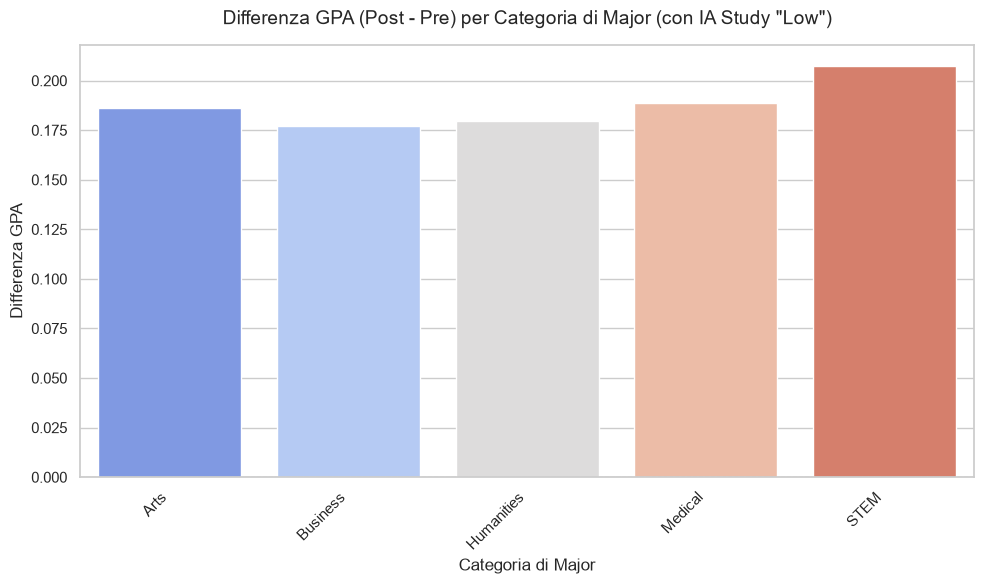

In [124]:
plt.figure(figsize=(10, 6))
sns.barplot(x=gpa_facoltaTotT.index, y=gpa_facoltaTotT.values, palette='coolwarm')
plt.title('Differenza GPA (Post - Pre) per Categoria di Major (con IA Study "Low")', fontsize=14, pad=15)
plt.xlabel('Categoria di Major', fontsize=12)
plt.ylabel('Differenza GPA', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

In [125]:
gpa_facoltaTotS = (gpa_facoltaSF - gpa_facoltaSI).sort_index(ascending=True)
for facolta, gpa in gpa_facoltaTotS.items():
    print(f"-> Differenza GPA in {facolta}: {gpa:.3f}")

-> Differenza GPA in Arts: 0.207
-> Differenza GPA in Business: 0.208
-> Differenza GPA in Humanities: 0.209
-> Differenza GPA in Medical: 0.213
-> Differenza GPA in STEM: 0.236


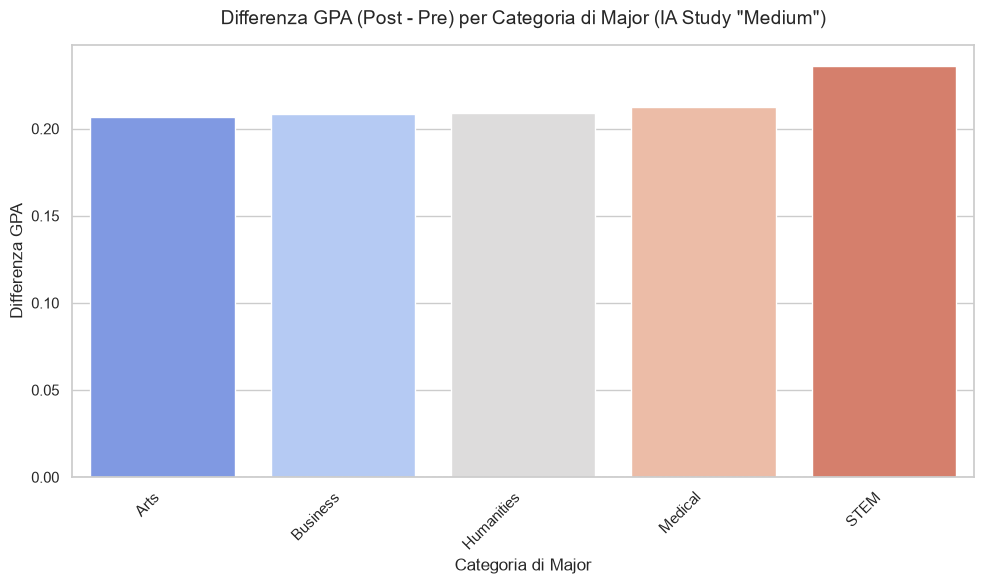

In [126]:
plt.figure(figsize=(10, 6))
sns.barplot(x=gpa_facoltaTotS.index, y=gpa_facoltaTotS.values, palette='coolwarm')
plt.title('Differenza GPA (Post - Pre) per Categoria di Major (IA Study "Medium")', fontsize=14, pad=15)
plt.xlabel('Categoria di Major', fontsize=12)
plt.ylabel('Differenza GPA', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

In [127]:
gpa_facoltaTotI = (gpa_facoltaIF - gpa_facoltaII).sort_index(ascending=True)
for facolta, gpa in gpa_facoltaTotI.items():
    print(f"-> Differenza GPA in {facolta}: {gpa:.3f}")

-> Differenza GPA in Arts: 0.167
-> Differenza GPA in Business: 0.162
-> Differenza GPA in Humanities: 0.178
-> Differenza GPA in Medical: 0.172
-> Differenza GPA in STEM: 0.179


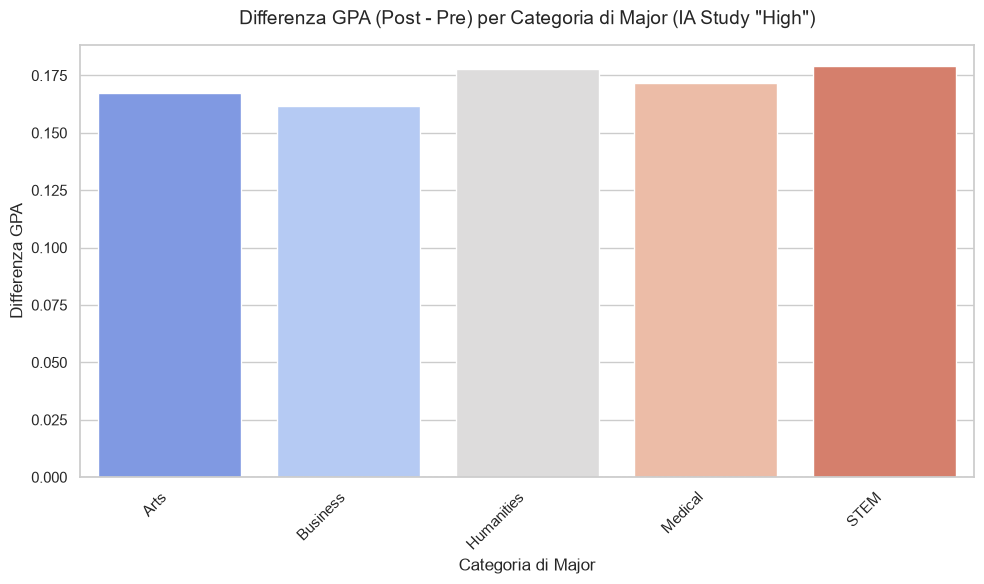

In [128]:
plt.figure(figsize=(10, 6))
sns.barplot(x=gpa_facoltaTotI.index, y=gpa_facoltaTotI.values, palette='coolwarm')
plt.title('Differenza GPA (Post - Pre) per Categoria di Major (IA Study "High")', fontsize=14, pad=15)
plt.xlabel('Categoria di Major', fontsize=12)
plt.ylabel('Differenza GPA', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

## Ore di Studio

In [129]:
dfTraditional["TotalHour"] = dfTraditional["Traditional_Study_Hours"] + dfTraditional["Weekly_GenAI_Hours"]
dfSemiIA["TotalHour"] = dfSemiIA["Traditional_Study_Hours"] + dfSemiIA["Weekly_GenAI_Hours"]
dfIA["TotalHour"] = dfIA["Traditional_Study_Hours"] + dfIA["Weekly_GenAI_Hours"]

mediaT = dfTraditional['TotalHour'].mean()
print("MEDIE ORE DI STUDIO PER CATEGORIA\n" + "-" * 50)
print(f"La medie di ore passate dalle persone che non usano assiduamente l'ia per studiare sono di {mediaT:.2f} ore")
print("-" * 50)

mediaS = dfSemiIA['TotalHour'].mean()

print(f"La medie di ore passate dalle persone che usano moderatamente l'ia per studiare sono di {mediaS:.2f} ore")
print("-" * 50)

mediaI = dfIA['TotalHour'].mean()

print(f"La medie di ore passate dalle persone che usano assiduamente l'ia per studiare sono di {mediaI:.2f} ore")

medie = [mediaT,mediaS,mediaI]

MEDIE ORE DI STUDIO PER CATEGORIA
--------------------------------------------------
La medie di ore passate dalle persone che non usano assiduamente l'ia per studiare sono di 12.84 ore
--------------------------------------------------
La medie di ore passate dalle persone che usano moderatamente l'ia per studiare sono di 18.24 ore
--------------------------------------------------
La medie di ore passate dalle persone che usano assiduamente l'ia per studiare sono di 33.16 ore


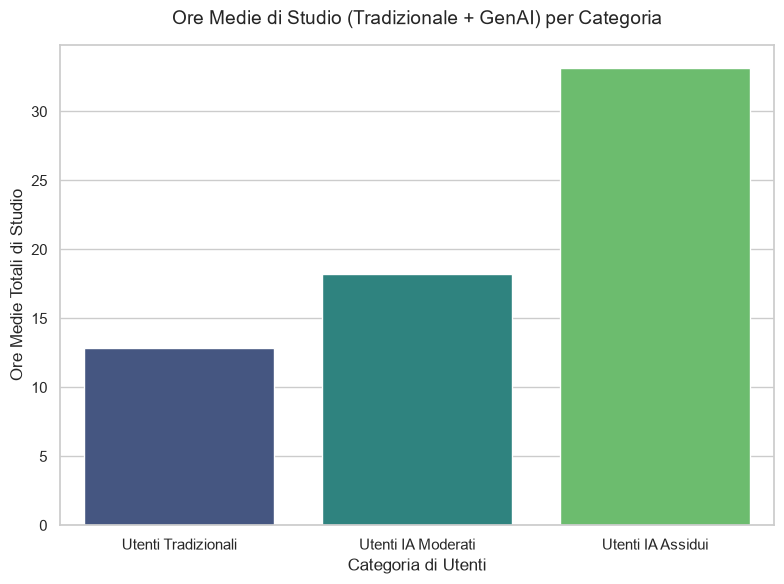

In [130]:
plt.figure(figsize=(8, 6))

mean_hours_df = pd.DataFrame({
    'Category': ['Utenti Tradizionali',"Utenti IA Moderati", 'Utenti IA Assidui'],
    'Mean_Study_Hours': medie
})

sns.barplot(
    x='Category',
    y='Mean_Study_Hours',
    data=mean_hours_df,
    palette='viridis'
)

plt.title('Ore Medie di Studio (Tradizionale + GenAI) per Categoria', fontsize=14, pad=15)
plt.xlabel('Categoria di Utenti', fontsize=12)
plt.ylabel('Ore Medie Totali di Studio', fontsize=12)
plt.tight_layout()
plt.show()

## Divisione per Esperienza

In [131]:
Beginner = len(dfIA[dfIA['Prompt_Engineering_Skill'] == "Beginner"])

print(f"Il numero di utenti con skill 'Beginner' che usano assiduamente l'IA è di {Beginner}")
print("-" * 50)

Intermediate = len(dfIA[dfIA['Prompt_Engineering_Skill'] == "Intermediate"])

print(f"Il numero di utenti con skill 'Intermediate' che usano assiduamente l'IA è di {Intermediate}")
print("-" * 50)

Advanced = len(dfIA[dfIA['Prompt_Engineering_Skill'] == "Advanced"])

print(f"Il numero di utenti con skill 'Advanced' che usano assiduamente l'IA è di {Advanced}")

categorie = [Beginner,Intermediate,Advanced]

Il numero di utenti con skill 'Beginner' che usano assiduamente l'IA è di 3023
--------------------------------------------------
Il numero di utenti con skill 'Intermediate' che usano assiduamente l'IA è di 3018
--------------------------------------------------
Il numero di utenti con skill 'Advanced' che usano assiduamente l'IA è di 2501


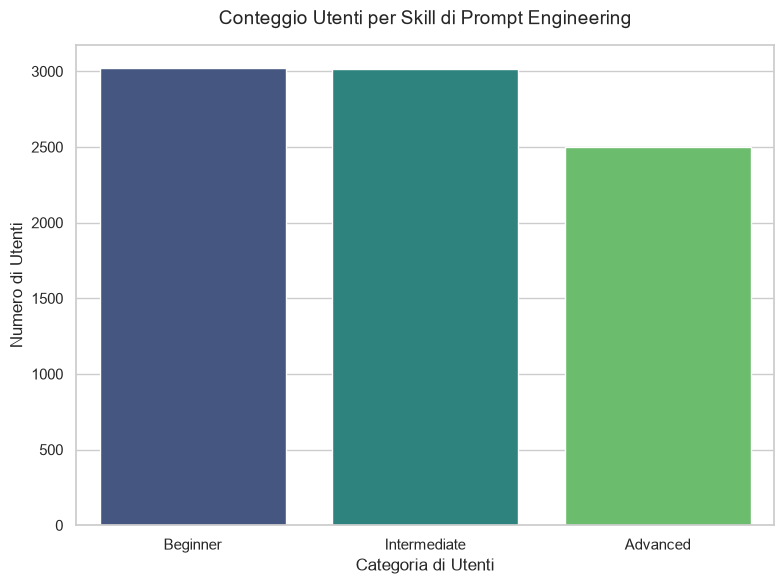

In [132]:
plt.figure(figsize=(8, 6))

counter_df = pd.DataFrame({
    'Category': ['Beginner',"Intermediate", 'Advanced'],
    'Counter': categorie
})

sns.barplot(
    x='Category',
    y='Counter',
    data=counter_df,
    palette='viridis'
)

plt.title('Conteggio Utenti per Skill di Prompt Engineering', fontsize=14, pad=15)
plt.xlabel('Categoria di Utenti', fontsize=12)
plt.ylabel('Numero di Utenti', fontsize=12)
plt.tight_layout()
plt.show()

In [133]:
df.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level,IAStudy
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High,Alto
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low,Basso
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium,Alto
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium,Basso
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium,Medio


## Correlazioni tra gli altri attributi

In [134]:
conditions = [
    df['IAStudy'] == "Alto",
    df['IAStudy'] == "Basso",
]
choices = ['3', '1']
df['IA_Study_Metric'] = np.select(conditions, choices, default='2')


In [135]:
conditions = [
    df['Burnout_Risk_Level'] == "High",
    df['Burnout_Risk_Level'] == "Low",
]
choices = ['3', '1']
df['Burnout_Risk_Level_Metric'] = np.select(conditions, choices, default='2')


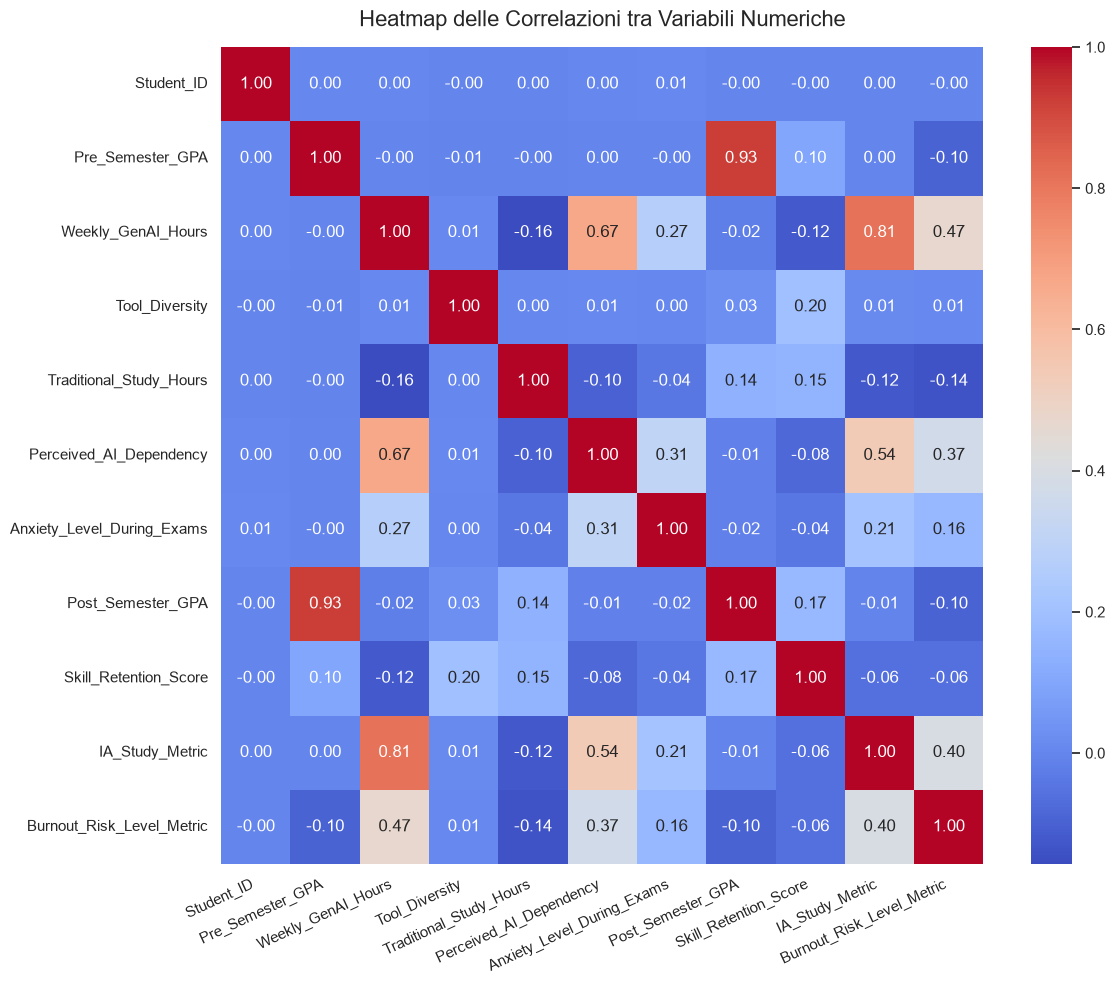

In [136]:
df['IA_Study_Metric'] = pd.to_numeric(df['IA_Study_Metric'])
df['Burnout_Risk_Level_Metric'] = pd.to_numeric(df['Burnout_Risk_Level_Metric'])

plt.figure(figsize=(12, 10))
sns.heatmap(df.select_dtypes(include=['number']).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Heatmap delle Correlazioni tra Variabili Numeriche', fontsize=16, pad=15)
plt.xticks(rotation=25, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Soglia di apprendimento

In [137]:
print("-" * 50 + "\n")
print("Media Apprendimento per studenti con basso utilizzo di IA \n")
skill_facoltaT = dfTraditional.groupby('Major_Category')['Skill_Retention_Score'].mean()
for facolta, gpa in skill_facoltaT.items():
    print(f"-> Media skill in {facolta}: {gpa:.3f}")

print("\n" + "-" * 50 + "\n")
print("Media Apprendimento per studenti con medio utilizzo di IA \n")
skill_facoltaS = dfSemiIA.groupby('Major_Category')['Skill_Retention_Score'].mean()
for facolta, gpa in skill_facoltaS.items():
    print(f"-> Media skill in {facolta}: {gpa:.3f}")

print("\n" + "-" * 50 + "\n")
print("Media Apprendimento per studenti con alto utilizzo di IA \n")
skill_facoltaI = dfIA.groupby('Major_Category')['Skill_Retention_Score'].mean()
for facolta, gpa in skill_facoltaI.items():
    print(f"-> Media skill in {facolta}: {gpa:.3f}")

--------------------------------------------------

Media Apprendimento per studenti con basso utilizzo di IA 

-> Media skill in Arts: 75.411
-> Media skill in Business: 75.237
-> Media skill in Humanities: 75.195
-> Media skill in Medical: 74.668
-> Media skill in STEM: 77.102

--------------------------------------------------

Media Apprendimento per studenti con medio utilizzo di IA 

-> Media skill in Arts: 76.193
-> Media skill in Business: 76.133
-> Media skill in Humanities: 75.677
-> Media skill in Medical: 76.372
-> Media skill in STEM: 78.400

--------------------------------------------------

Media Apprendimento per studenti con alto utilizzo di IA 

-> Media skill in Arts: 73.542
-> Media skill in Business: 71.885
-> Media skill in Humanities: 72.991
-> Media skill in Medical: 72.850
-> Media skill in STEM: 72.822


In [138]:
skill_facoltaTot1 = (skill_facoltaT - skill_facoltaS).sort_index(ascending=True)
for facolta, gpa in skill_facoltaTot1.items():
    print(f"-> Differenza GPA in {facolta}: {gpa:.3f}")

-> Differenza GPA in Arts: -0.781
-> Differenza GPA in Business: -0.896
-> Differenza GPA in Humanities: -0.483
-> Differenza GPA in Medical: -1.704
-> Differenza GPA in STEM: -1.297


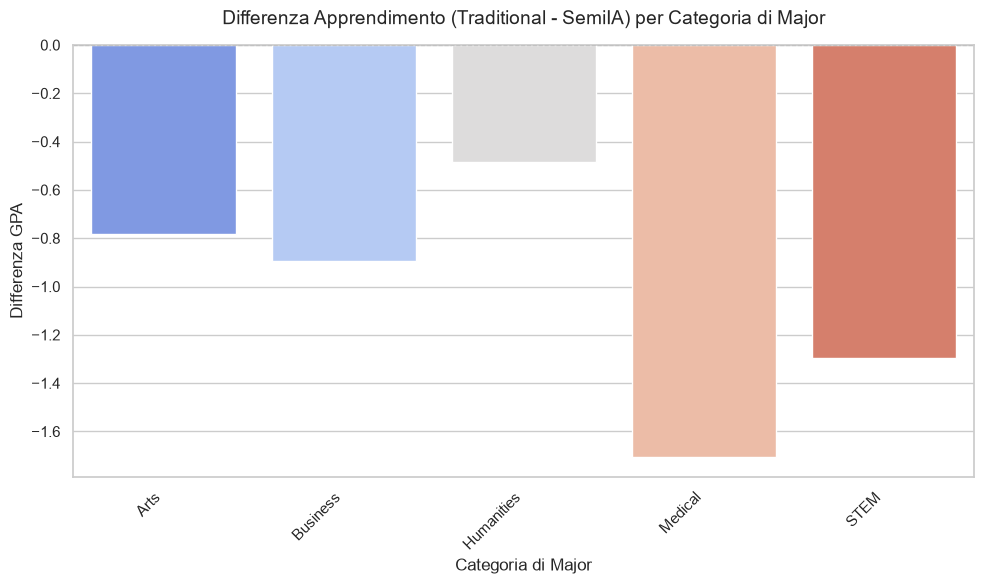

In [139]:
plt.figure(figsize=(10, 6))
sns.barplot(x=skill_facoltaTot1.index, y=skill_facoltaTot1.values, palette='coolwarm')
plt.title('Differenza Apprendimento (Traditional - SemiIA) per Categoria di Major', fontsize=14, pad=15)
plt.xlabel('Categoria di Major', fontsize=12)
plt.ylabel('Differenza GPA', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

In [140]:
skill_facoltaTot2 = (skill_facoltaT - skill_facoltaI).sort_index(ascending=True)
for facolta, gpa in skill_facoltaTot2.items():
    print(f"-> Differenza GPA in {facolta}: {gpa:.3f}")

-> Differenza GPA in Arts: 1.869
-> Differenza GPA in Business: 3.352
-> Differenza GPA in Humanities: 2.204
-> Differenza GPA in Medical: 1.818
-> Differenza GPA in STEM: 4.280


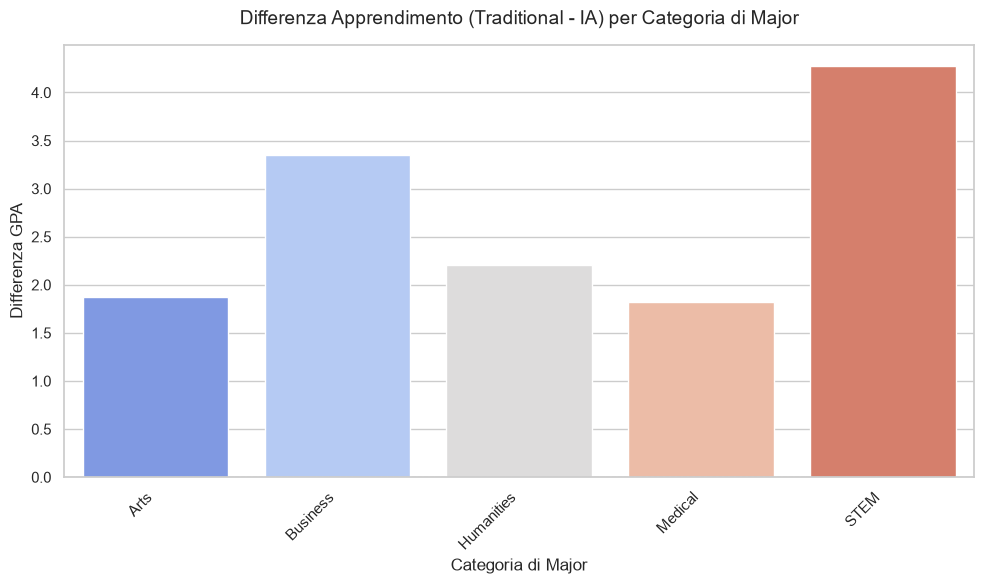

In [141]:
plt.figure(figsize=(10, 6))
sns.barplot(x=skill_facoltaTot2.index, y=skill_facoltaTot2.values, palette='coolwarm')
plt.title('Differenza Apprendimento (Traditional - IA) per Categoria di Major', fontsize=14, pad=15)
plt.xlabel('Categoria di Major', fontsize=12)
plt.ylabel('Differenza GPA', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

In [142]:
skill_facoltaTot3 = (skill_facoltaS - skill_facoltaI).sort_values(ascending=True)
for facolta, gpa in skill_facoltaTot3.items():
    print(f"-> Differenza GPA in {facolta}: {gpa:.3f}")

-> Differenza GPA in Arts: 2.651
-> Differenza GPA in Humanities: 2.687
-> Differenza GPA in Medical: 3.522
-> Differenza GPA in Business: 4.248
-> Differenza GPA in STEM: 5.577


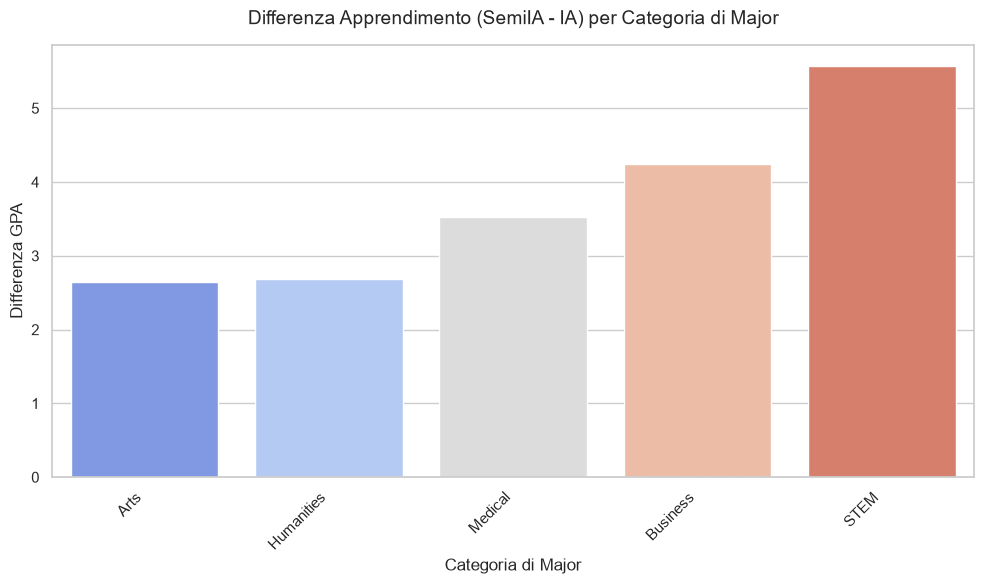

In [143]:
plt.figure(figsize=(10, 6))
sns.barplot(x=skill_facoltaTot3.index, y=skill_facoltaTot3.values, palette='coolwarm')
plt.title('Differenza Apprendimento (SemiIA - IA) per Categoria di Major', fontsize=14, pad=15)
plt.xlabel('Categoria di Major', fontsize=12)
plt.ylabel('Differenza GPA', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

## Ansia con studio IA

In [144]:
Low = len(dfIA[dfIA['Burnout_Risk_Level'] == "Low"])

print(f"Il numero di utenti con rischio 'Low' di Burnout che usano assiduamente l'IA è di {Low}")
print("-" * 50)

Medium = len(dfIA[dfIA['Burnout_Risk_Level'] == "Medium"])

print(f"Il numero di utenti con rischio 'Medium' di Burnout che usano assiduamente l'IA è di {Medium}")
print("-" * 50)

High = len(dfIA[dfIA['Burnout_Risk_Level'] == "High"])

print(f"Il numero di utenti con rischio 'High di Burnout' che usano assiduamente l'IA è di {High}")

categorie = [Low,Medium,High]

Il numero di utenti con rischio 'Low' di Burnout che usano assiduamente l'IA è di 492
--------------------------------------------------
Il numero di utenti con rischio 'Medium' di Burnout che usano assiduamente l'IA è di 2519
--------------------------------------------------
Il numero di utenti con rischio 'High di Burnout' che usano assiduamente l'IA è di 5531


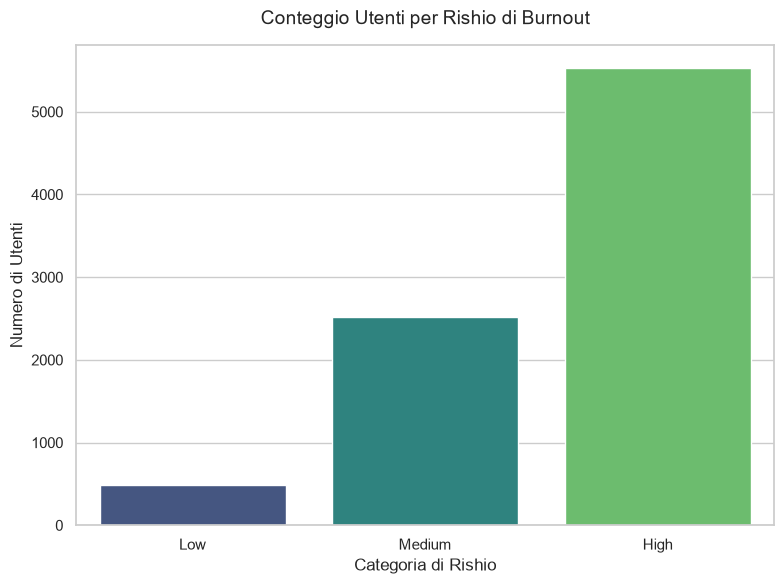

In [145]:
plt.figure(figsize=(8, 6))

counter_df = pd.DataFrame({
    'Category': ['Low',"Medium", 'High'],
    'Counter': categorie
})

sns.barplot(
    x='Category',
    y='Counter',
    data=counter_df,
    palette='viridis'
)

plt.title('Conteggio Utenti per Rishio di Burnout', fontsize=14, pad=15)
plt.xlabel('Categoria di Rishio', fontsize=12)
plt.ylabel('Numero di Utenti', fontsize=12)
plt.tight_layout()
plt.show()

## Correlazione tra Ansia e Burnout

In [146]:
conditions = [
    dfIA['Burnout_Risk_Level'] == "High",
    dfIA['Burnout_Risk_Level'] == "Low",
]
choices = ['3', '1']
dfIA['Burnout_Risk_LevelM'] = np.select(conditions, choices, default='2')
dfIA.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level,TotalHour,Burnout_Risk_LevelM
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High,31.44,3
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium,31.61,2
6,100007,STEM,Freshman,3.622,31.41,Summarizing_Reading,Advanced,5,True,13.11,8,Allowed_With_Citation,7,4.000,67.97,Medium,44.52,2
9,100010,Business,Sophomore,3.046,19.99,Debugging/Troubleshooting,Intermediate,2,True,12.49,3,Strict_Ban,8,2.978,87.18,High,32.48,3
24,100025,Humanities,Freshman,2.364,28.72,Copywriting/Drafting,Beginner,1,False,8.24,8,Strict_Ban,7,2.588,63.38,Medium,36.96,2


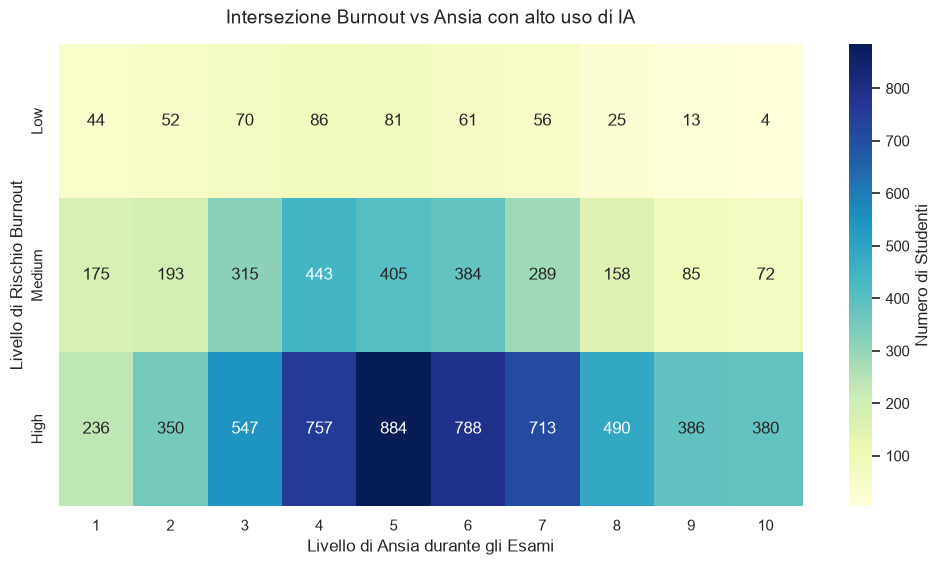

In [147]:
mapping_burnout = {'1': 'Low', '2': 'Medium', '3': 'High'}

conditional_table = pd.crosstab(
    index=dfIA['Burnout_Risk_LevelM'],
    columns=dfIA['Anxiety_Level_During_Exams']
)

conditional_table.index = conditional_table.index.map(mapping_burnout)

plt.figure(figsize=(12, 6))
sns.heatmap(
    conditional_table,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    cbar_kws={'label': 'Numero di Studenti'}
)

plt.title('Intersezione Burnout vs Ansia con alto uso di IA', fontsize=14, pad=15)
plt.xlabel('Livello di Ansia durante gli Esami', fontsize=12)
plt.ylabel('Livello di Rischio Burnout', fontsize=12)
plt.show()